<h1> Methods of Visualization for Zebra Embryos (Early Development) <h1>

## Initialization and preloading data

In [1]:
# Initialize the cloud data manager and inspect the active TDA parameters.
# Summary: Create a CloudDataManager, optionally configure/load TDA data, and inspect its parameters.
from tda_module.v3_1 import CloudDataManager

# Instantiate the manager used by all later notebook cells.
manager = CloudDataManager()
# manager.load_groups_from_directory("/workspaces/Cellular-TDA/data/Data 8:11")

# manager.TDA.compute_all_persistence_diagrams()
# manager.TDA.compute_all_persistence_landscapes(n_layers=2,resolution=500)


manager._tda_params

# Conclusion: The manager is ready for loading data and configuring TDA computations.


In [2]:
# Load the previously saved dataset and report how many groups it contains.
# Summary: Load the saved group dataset and report the number of groups available for analysis.
path = "../notebooks/currentData.pkl"
# manager.save(path)  # Run after loading data and computing landscapes
# Restore the persisted manager so PCA can use the computed feature data.
manager = CloudDataManager.load(path)
print(len(manager.groups))

# Conclusion: The saved dataset is available for the visualization workflow.


843


## Method 1 PCA change of axis Plots

In [3]:
# Define PCA comparisons, colors, and a multi-panel interactive Plotly layout.
# Summary: Define ten PCA comparison configurations, compute each PCA result, and combine Plotly traces into a 5-by-2 figure.
# Define the PCA comparisons used to contrast conditions and homology dimensions.
plot1 = {
    "embryo_name": "All",
    "condition": [ "control-m", "epha2a-wm", "epha2a-sm"],  
    "properties": [0]
}
plot2 = {
    "embryo_name": "All",
    "condition": [ "control-m", "epha2a-wm", "epha2a-sm"],  
    "properties": [1]
}
plot3 = {
    "embryo_name": "All",
    "condition": [ "control-l", "epha2a-wl"],
    "properties": [0]
}
plot4 = {
    "embryo_name": "All",
    "condition": [ "control-l", "epha2a-wl"],
    "properties": [1]
}
plot5 = {
    "embryo_name": "All",
    "condition": [ "control-m", "control-l" ],
    "properties": [0]
}
plot6 = {
    "embryo_name": "All",
    "condition": [ "control-m", "control-l" ],
    "properties": [1]
}
plot7 = {
    "embryo_name": "All",
    "condition": [ "control-m", "control-l", "epha2a-wl",  ],
    "properties": [0]
}   
plot8 = {
    "embryo_name": "All",
    "condition": [ "control-m", "control-l", "epha2a-wl" ],
    "properties": [ 1]
}
plot9 = {
    "embryo_name": "All",  
    "condition": [ "control-m", "control-l", "epha2a-sm" ],
    "properties": [0]
}
plot10 = {
    "embryo_name": "All", 
    "condition": [ "control-m", "control-l", "epha2a-sm" ],
    "properties": [1]
}

from plotly.subplots import make_subplots

all_plots = [plot1, plot2, plot3, plot4, plot5, plot6, plot7, plot8, plot9, plot10]
features = {
    "marker_symbols": {"CM1": "circle"},
    "markers": {"size": 10},
    "condition_colors": {
        "control-l": "#260eff",
        "control-m": "#260eff",
        "epha2a-wm": "#ff0e16",
        "epha2a-wl": "#ff0e16",
        "epha2a-sm": "#ff0e16",
    },
    "group_colors": {"CL1": "#260eff"},
}

# Create one subplot for each comparison before adding its PCA traces.
fig = make_subplots(
    rows=5,
    cols=2,
    vertical_spacing=0.04,
    subplot_titles=[f"Plot {i}" for i in range(1, 11)],
)
for annotation, pca_key in zip(fig.layout.annotations, all_plots):
    conditions = pca_key["condition"]
    if isinstance(conditions, str):
        conditions = [conditions]
    properties = pca_key["properties"]
    annotation.text = (
        f"{' + '.join(conditions)} | "
        f"H{', '.join(str(prop) for prop in properties)}"
    )

# Compute and add the traces for each PCA comparison.
for i, pca_key in enumerate(all_plots):
    pca_result = manager.compute_pca(pca_key)
    plot_fig = manager.plot_interactive_plotly(
        pca_key,
        showTrajectories=False,
        features=features,
    )

    row = i // 2 + 1
    col = i % 2 + 1
    legend_id = "legend" if i == 0 else f"legend{i + 1}"
    for trace in plot_fig.data:
        trace.legend = legend_id
        fig.add_trace(trace, row=row, col=col)

    # Keep each subplot's PCA bounds fixed when legend entries are hidden.
    fig.update_xaxes(
        range=plot_fig.layout.xaxis.range,
        title_text=(
            f"PC1 ({pca_result['explained_variance_ratio'][0] * 100:.2f}%)"
        ),
        autorange=False,
        row=row,
        col=col,
    )
    fig.update_yaxes(
        range=plot_fig.layout.yaxis.range,
        title_text=(
            f"PC2 ({pca_result['explained_variance_ratio'][1] * 100:.2f}%)"
        ),
        autorange=False,
        row=row,
        col=col,
    )

# Put an independent legend in the bottom band of each subplot.
legend_band = 0.035
for i in range(len(all_plots)):
    axis_number = i + 1
    suffix = "" if axis_number == 1 else str(axis_number)
    xaxis = fig.layout[f"xaxis{suffix}"]
    yaxis = fig.layout[f"yaxis{suffix}"]

    x0, x1 = xaxis.domain
    y0, y1 = yaxis.domain
    legend_y = y0 + legend_band
    yaxis.domain = [legend_y, y1]

    legend_id = "legend" if i == 0 else f"legend{i + 1}"
    fig.update_layout(**{
        legend_id: dict(
            orientation="h",
            x=(x0 + x1) / 2,
            xanchor="center",
            y=legend_y,
            yanchor="top",
            font=dict(size=9),
        )
    })

fig.update_layout(height=1600, width=1200, title_text="PCA Plots")


# Conclusion: Ten PCA scatter plots are assembled with consistent axes and legends.


## Method 2 Average Directtion Displayment

In [4]:
# Compute PCA trajectories and build sequentially reoriented interactive paths.
# Summary: Compute PCA trajectories, reorient each path sequentially, and render collective embryo movement in interactive PCA plots.
import ipywidgets as widgets
import numpy as np
import plotly.graph_objects as go
from IPython.display import display
from plotly.colors import qualitative
# From previous cell, all_plots is already defined as a list of PCA comparison configurations.
# all_plots = [plot1, plot2, plot3, plot4, plot5, plot6, plot7, plot8, plot9, plot10] 

# Store trajectory coordinates and explained-variance metadata for every comparison.
sequential_results = []

additional_plots = [{
    "embryo_name": "All",
    "condition": "All",
    "properties": [0],
}, {
    "embryo_name": "All",
    "condition": "All",
    "properties": [1],
}, {
    "embryo_name": "All",
    "condition": "All",
    "properties": [1,0],
}]

# Process each configured PCA comparison independently. Manager previously computed PCA results are reused to avoid redundant calculations.
for pca_key in [*all_plots, *additional_plots]:
    pca_result = manager.compute_pca(pca_key, n_components=2)
    coords = np.asarray(pca_result["transformed"])
    row_order = pca_result["row_order"]
    trajectories = sorted(
        {
            (manager.groups[group_id].embryo_name, prop)
            for group_id, prop in row_order
        },
        key=lambda item: (item[0], item[1]),
    )

# Build one ordered path for each embryo and homology property.
    trajectory_data = []
    all_points = []
# Recover observations in timestep order for the current trajectory.
    for embryo_name, prop in trajectories:
        indices = [
            idx
            for idx, (group_id, row_prop) in enumerate(row_order)
            if manager.groups[group_id].embryo_name == embryo_name
            and row_prop == prop
        ]
        indices.sort(key=lambda idx: manager.groups[row_order[idx][0]].timestep)
        trajectory = coords[indices]
        original_vectors = np.diff(trajectory, axis=0)
        current_point = trajectory[0].copy()
        path_points = [current_point.copy()]
        timesteps = [manager.groups[row_order[indices[0]][0]].timestep]

# Reorient later displacement vectors toward the accumulated direction.
        for vector_idx, vector in enumerate(original_vectors):
            if vector_idx == 0:
                adjusted_vector = vector.copy()
            else:
                cumulative_vector = original_vectors[: vector_idx + 1].sum(axis=0)
                cumulative_norm = np.linalg.norm(cumulative_vector)
                if cumulative_norm <= np.finfo(float).eps:
                    continue
                adjusted_vector = (
                    cumulative_vector / cumulative_norm
                ) * np.linalg.norm(vector)

            if np.linalg.norm(adjusted_vector) <= np.finfo(float).eps:
                continue

            current_point = current_point + adjusted_vector
            path_points.append(current_point.copy())
            endpoint_idx = indices[vector_idx + 1]
            timesteps.append(
                manager.groups[row_order[endpoint_idx][0]].timestep
            )

        path_points = np.asarray(path_points)
        all_points.extend(path_points)
        trajectory_data.append({
            "name": f"{embryo_name} | H{prop}",
            "legendgroup": f"{embryo_name}-H{prop}",
            "points": path_points,
            "timesteps": timesteps,
        })

    conditions = pca_key["condition"]
    if isinstance(conditions, str):
        conditions = [conditions]
    title = (
        f"{' + '.join(conditions)} | "
        f"H{', '.join(map(str, pca_key['properties']))}"
    )
    sequential_results.append({
        "title": title,
        "explained_variance_ratio": pca_result["explained_variance_ratio"],
        "trajectories": trajectory_data,
        "all_points": np.asarray(all_points),
    })

# Create a dropdown so one sequential PCA comparison can be viewed at a time.
sequential_plot_picker = widgets.Dropdown(
    options=[
        (f"{index + 1}: {result['title']}", index)
        for index, result in enumerate(sequential_results)
    ],
    value=0,
    description="Plot",
    layout=widgets.Layout(width="700px"),
)
trajectory_colors = qualitative.Dark24


def show_sequential_pca_plot(plot_index):
    """Display one sequentially reoriented PCA trajectory plot."""
    result = sequential_results[plot_index]
    fig = go.Figure()

    # Add each embryo trajectory and mark its starting point with an X.
    for trajectory_idx, trajectory in enumerate(result["trajectories"]):
        points = trajectory["points"]
        color = trajectory_colors[trajectory_idx % len(trajectory_colors)]
        endpoint_labels = [""] * len(points)
        endpoint_labels[-1] = trajectory["name"]

        fig.add_trace(
            go.Scatter(
                x=points[:, 0],
                y=points[:, 1],
                customdata=np.asarray(trajectory["timesteps"]).reshape(-1, 1),
                mode="lines+markers+text",
                text=endpoint_labels,
                textposition="top right",
                name=trajectory["name"],
                legendgroup=trajectory["legendgroup"],
                marker={"size": 6, "color": color},
                line={"width": 1.8, "color": color},
                hovertemplate=(
                    f"{trajectory['name']}<br>"
                    "Timestep: %{customdata[0]}<br>"
                    "PC1: %{x:.3f}<br>PC2: %{y:.3f}<extra></extra>"
                ),
            )
        )
        fig.add_trace(
            go.Scatter(
                x=[points[0, 0]],
                y=[points[0, 1]],
                mode="markers",
                marker={"symbol": "x", "size": 10, "color": "black"},
                name=f"Start: {trajectory['name']}",
                legendgroup=trajectory["legendgroup"],
                showlegend=False,
                hoverinfo="skip",
            )
        )

    # Keep axis limits fixed for the selected comparison and show variance labels.
    points = result["all_points"]
    x_min, y_min = points.min(axis=0)
    x_max, y_max = points.max(axis=0)
    x_padding = (x_max - x_min) * 0.2 if x_max > x_min else 0.1
    y_padding = (y_max - y_min) * 0.2 if y_max > y_min else 0.1
    variance_ratio = result["explained_variance_ratio"]

    fig.update_layout(
        title=result["title"],
        height=750,
        width=1100,
        hovermode="closest",
        xaxis={
            "title": f"PC1 ({variance_ratio[0]:.1%})",
            "range": [x_min - x_padding, x_max + x_padding],
            "autorange": False,
            "ticks": "outside",
            "nticks": 8,
            "tickformat": ".2f",
        },
        yaxis={
            "title": f"PC2 ({variance_ratio[1]:.1%})",
            "range": [y_min - y_padding, y_max + y_padding],
            "autorange": False,
        },
        legend={"groupclick": "togglegroup"},
        margin={"l": 70, "r": 20, "t": 70, "b": 60},
    )
    display(fig)


# Refresh the figure whenever the selected dropdown value changes.
sequential_plot_output = widgets.interactive_output(
    show_sequential_pca_plot,
    {"plot_index": sequential_plot_picker},
)
display(
    widgets.VBox(
        [
            widgets.HBox([sequential_plot_picker]),
            sequential_plot_output,
        ]
    )
)
#add an average vector to all control-m and control-l then an average vector for both. Same for epha2a. 


In [5]:
# Import plotting and clustering utilities and define shared PCA helper functions.
# Summary: Import visualization/clustering dependencies and define reusable helpers for titles, homology splitting, and normalization.
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import to_rgb
from sklearn.cluster import KMeans


# These helpers keep plot labeling and numeric scaling consistent across cells.
# Shared helpers

def plot_title(pca_key, component_count):
    conditions = pca_key["condition"]
    if isinstance(conditions, str):
        conditions = [conditions]

    properties = ", ".join(
        f"H{prop}" for prop in pca_key["properties"]
    )

    return (
        f"{' + '.join(conditions)} | "
        f"{properties} | "
        f"{component_count} PCA components"
    )


def split_by_homology(results):
    h0 = [
        result
        for result in results
        if 0 in result["pca_key"]["properties"]
    ]
    h1 = [
        result
        for result in results
        if 1 in result["pca_key"]["properties"]
    ]
    return h0, h1


def normalize(values, low, high, default):
    if np.ptp(values) == 0:
        return np.full(values.shape, default)

    return np.interp(
        values,
        (values.min(), values.max()),
        (low, high),
    )

# Conclusion: Shared title, homology-splitting, and normalization helpers are available to later cells.


In [6]:
# Compute PCA representations for all comparison plots using homology-specific component counts.
# Summary: Compute PCA representations for every plot, using five components for H0 and fifteen for H1.
# Step 1: Compute PCA for every plot.
# H0 uses 5 components; H1 uses 15 components.

pca_results = []

# Run the manager’s PCA calculation with the component count appropriate to the homology.
for pca_key in all_plots:
    requested_components = (
        15 if 1 in pca_key["properties"] else 5
    )

    pca_result = manager.compute_pca(
        pca_key,
        n_components=requested_components,
    )

    pca_results.append(
        {
            "pca_key": pca_key,
            "pca_result": pca_result,
            "transformed": np.asarray(
                pca_result["transformed"]
            ),
            "requested_components": requested_components,
        }
    )

# Conclusion: PCA scores and metadata are stored for every plot and ready for variance analysis.


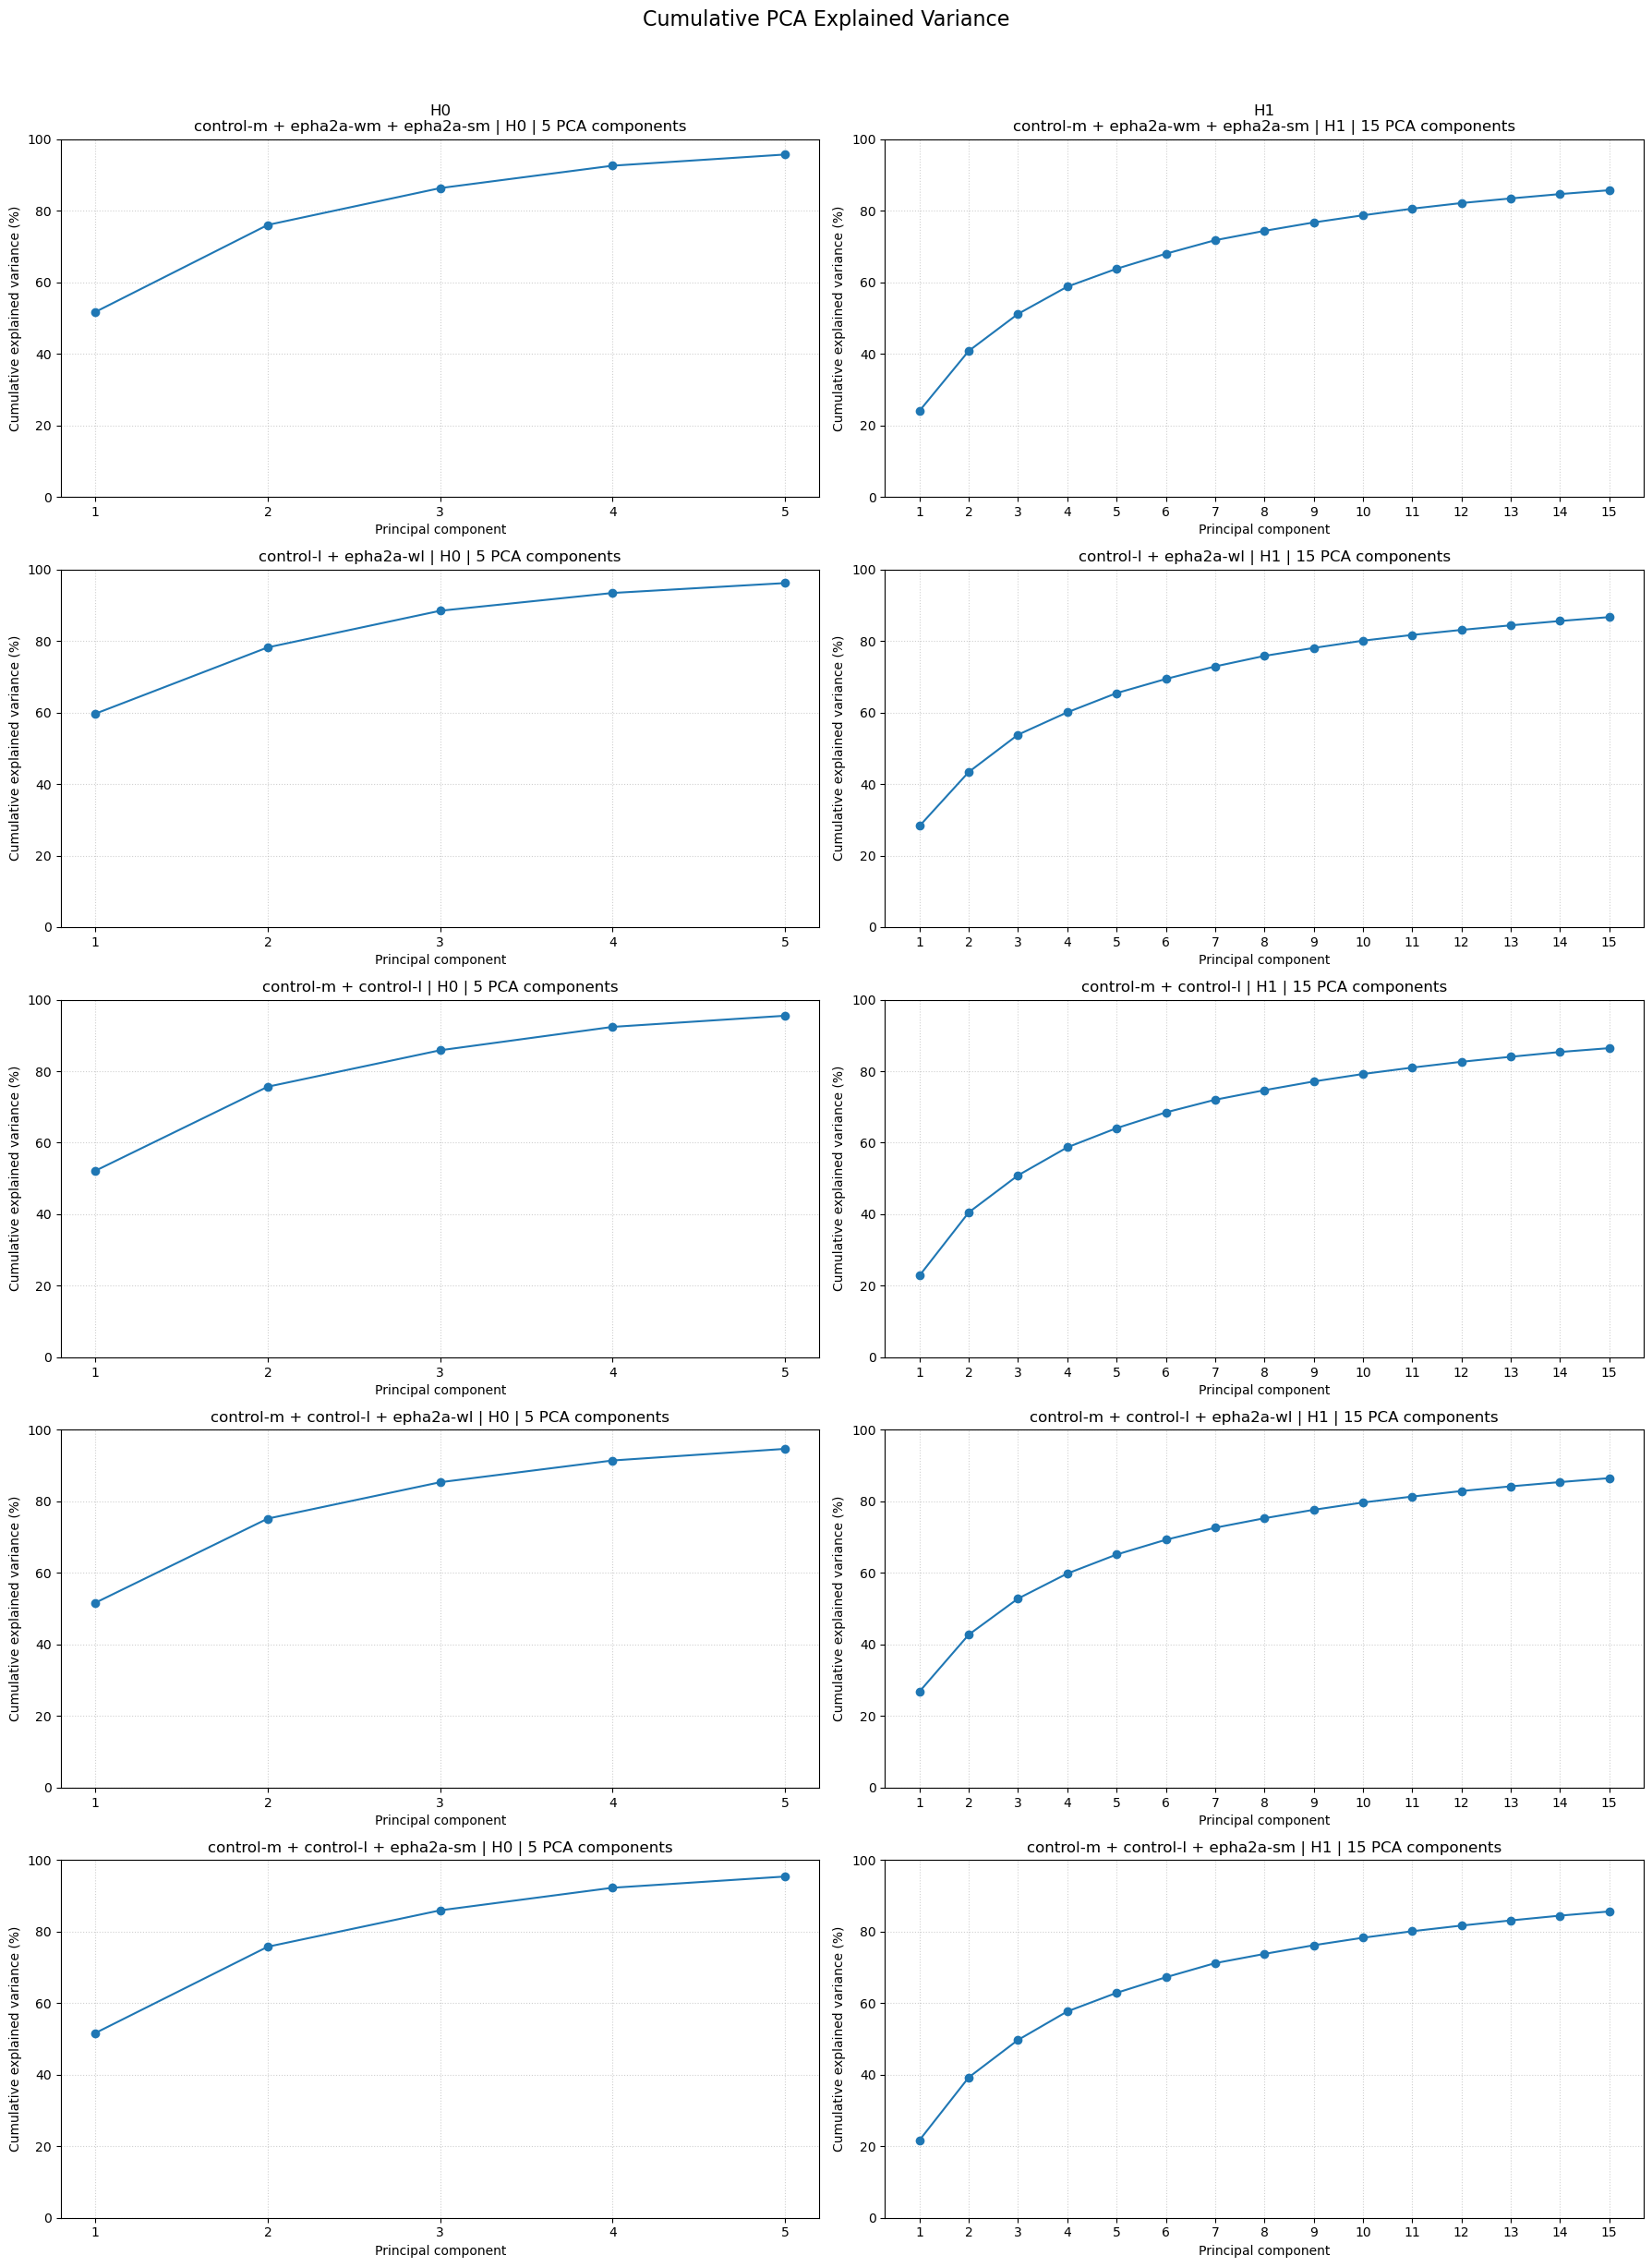

In [7]:
# Plot cumulative explained variance separately for H0 and H1 PCA results.
# Summary: Plot cumulative explained variance for each H0 and H1 PCA result in aligned comparison columns.
# Step 2: Plot cumulative explained variance.
# Column 1: H0
# Column 2: H1

# Arrange PCA records into the H0 and H1 plot columns.
h0_results, h1_results = split_by_homology(pca_results)

n_rows = max(
    1,
    len(h0_results),
    len(h1_results),
)

fig, axes = plt.subplots(
    n_rows,
    2,
    figsize=(18, 5 * n_rows),
    squeeze=False,
)

for column, results in enumerate((h0_results, h1_results)):
    for row, result in enumerate(results):
        explained_variance_ratio = np.asarray(
            result["pca_result"]["explained_variance_ratio"]
        )

        components = np.arange(
            1,
            len(explained_variance_ratio) + 1,
        )
        cumulative_variance = (
            np.cumsum(explained_variance_ratio) * 100
        )

        ax = axes[row, column]
        ax.plot(components, cumulative_variance, marker="o")
        ax.set_title(
            plot_title(
                result["pca_key"],
                result["requested_components"],
            )
        )
        ax.set_xlabel("Principal component")
        ax.set_ylabel("Cumulative explained variance (%)")
        ax.set_xticks(components)
        ax.set_ylim(0, 100)
        ax.grid(True, linestyle=":", alpha=0.6)

# Hide unused axes so both columns share the same grid size.
    for row in range(len(results), n_rows):
        axes[row, column].set_visible(False)

axes[0, 0].set_title("H0\n" + axes[0, 0].get_title())
axes[0, 1].set_title("H1\n" + axes[0, 1].get_title())

fig.suptitle(
    "Cumulative PCA Explained Variance",
    fontsize=16,
)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()


# Conclusion: These curves show how many principal components are needed to capture the desired variance.


In [8]:
# Re-run PCA with clustering-specific component counts for H0 and H1.
# Summary: Recompute PCA with the reduced component counts used as inputs to K-means clustering.
# Step 3: Re-run PCA for clustering.
# H0 uses 3 components; H1 uses 5 components.

clustering_results = []

# Recompute each comparison with only the components needed for clustering.
for pca_key in all_plots:
    requested_components = (
        3 if 0 in pca_key["properties"] else 5
    )

    pca_result = manager.compute_pca(
        pca_key,
        n_components=requested_components,
    )

    clustering_results.append(
        {
            "pca_key": pca_key,
            "pca_result": pca_result,
            "transformed": np.asarray(
                pca_result["transformed"]
            ),
            "requested_components": requested_components,
        }
    )

h0_clustering_results, h1_clustering_results = (
    split_by_homology(clustering_results)
)

# Conclusion: Homology-specific PCA scores are prepared for K-means clustering and elbow analysis.


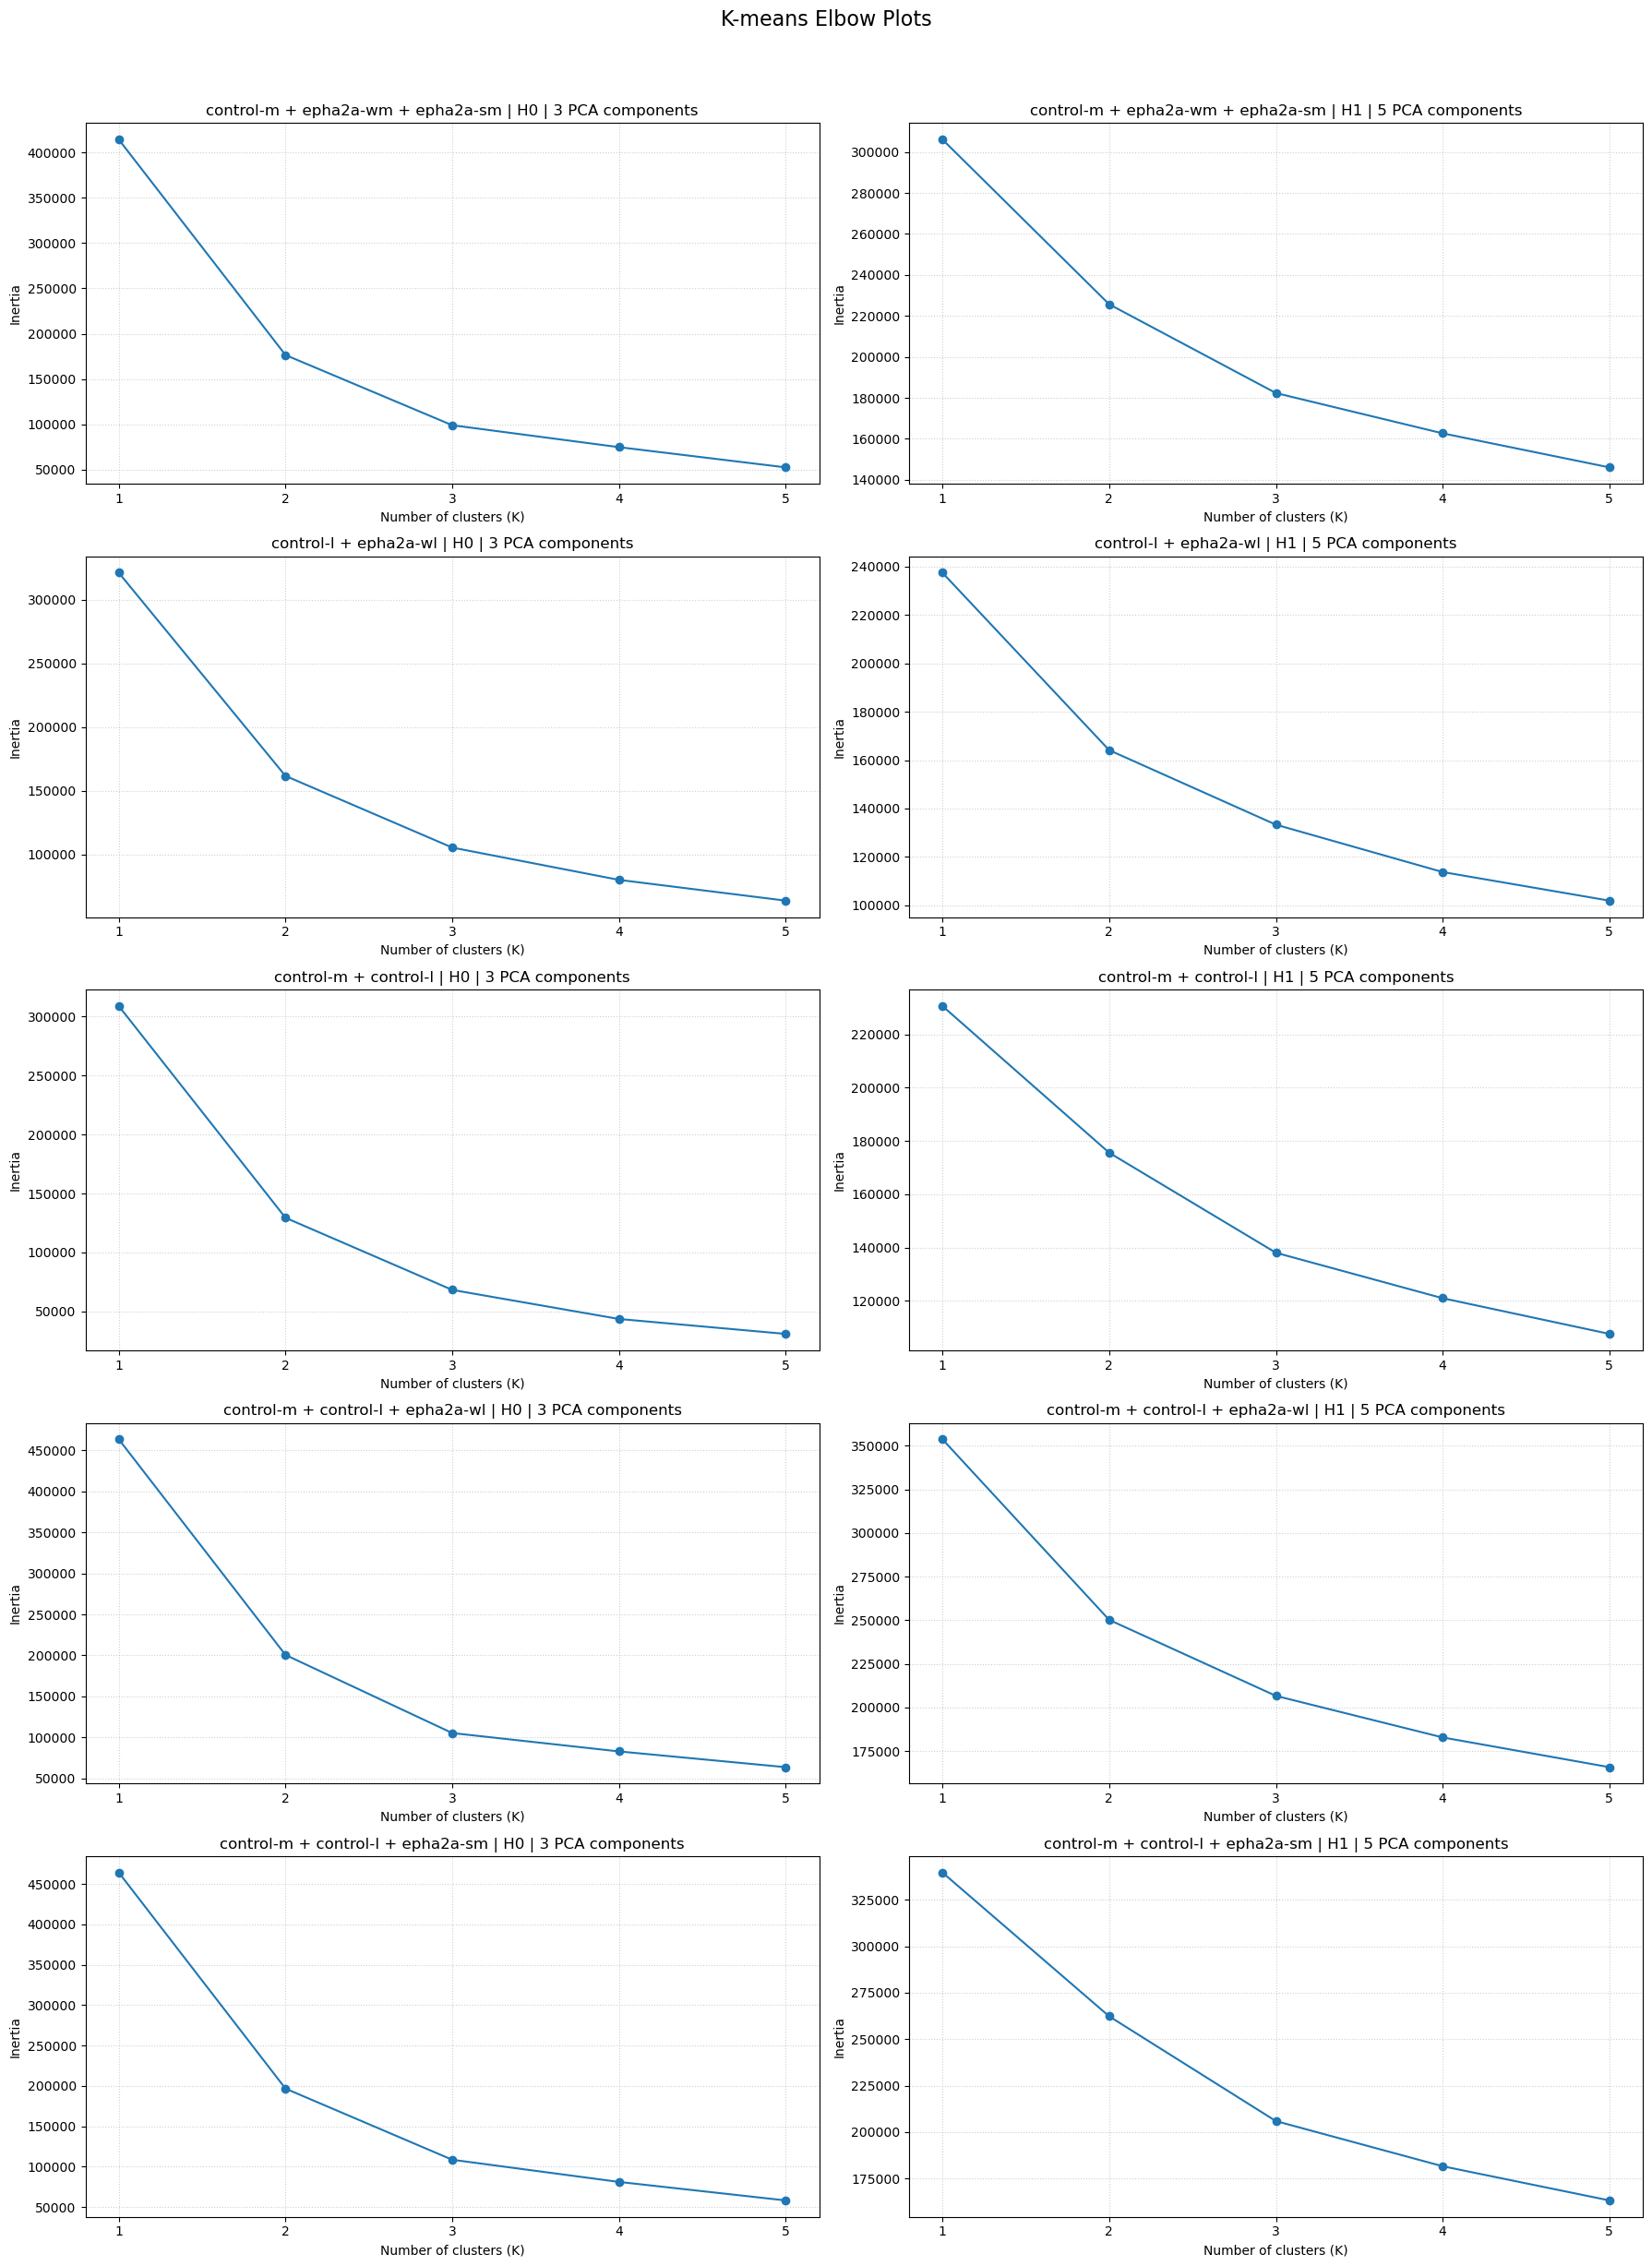

In [9]:
# Evaluate K-means inertia for one through five clusters to support cluster-count selection.
# Summary: Calculate K-means inertia for K values from one to five and plot elbow curves for H0 and H1.
# Step 4: Plot K-means elbow curves.
# K ranges from 1 through 5.
# Column 1: H0
# Column 2: H1

n_rows = max(
    1,
    len(h0_clustering_results),
    len(h1_clustering_results),
)

fig, axes = plt.subplots(
    n_rows,
    2,
    figsize=(18, 5 * n_rows),
    squeeze=False,
)

# Generate elbow curves independently for H0 and H1.
for column, results in enumerate(
    (h0_clustering_results, h1_clustering_results)
):
    for row, result in enumerate(results):
        transformed = result["transformed"]

        if transformed.ndim != 2:
            raise ValueError(
                "The PCA result must be a two-dimensional array."
            )

        if transformed.shape[0] < 5:
            raise ValueError(
                f"{plot_title(result['pca_key'], result['requested_components'])} "
                "has fewer than five samples."
            )

        cluster_counts = range(1, 6)
        inertias = []

# Fit each candidate cluster count and record its inertia.
        for k in cluster_counts:
            kmeans = KMeans(
                n_clusters=k,
                random_state=42,
                n_init=10,
            )
            inertias.append(
                kmeans.fit(transformed).inertia_
            )

        ax = axes[row, column]
# Plot inertia against K so potential elbows can be compared visually.
        ax.plot(
            list(cluster_counts),
            inertias,
            marker="o",
        )
        ax.set_title(
            plot_title(
                result["pca_key"],
                result["requested_components"],
            )
        )
        ax.set_xlabel("Number of clusters (K)")
        ax.set_ylabel("Inertia")
        ax.set_xticks(range(1, 6))
        ax.grid(True, linestyle=":", alpha=0.6)

    for row in range(len(results), n_rows):
        axes[row, column].set_visible(False)

axes[0, 0].set_title(axes[0, 0].get_title())
axes[0, 1].set_title(axes[0, 1].get_title())

fig.suptitle(
    "K-means Elbow Plots",
    fontsize=16,
)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

# Conclusion: The elbow plots provide an empirical guide for choosing the number of clusters.


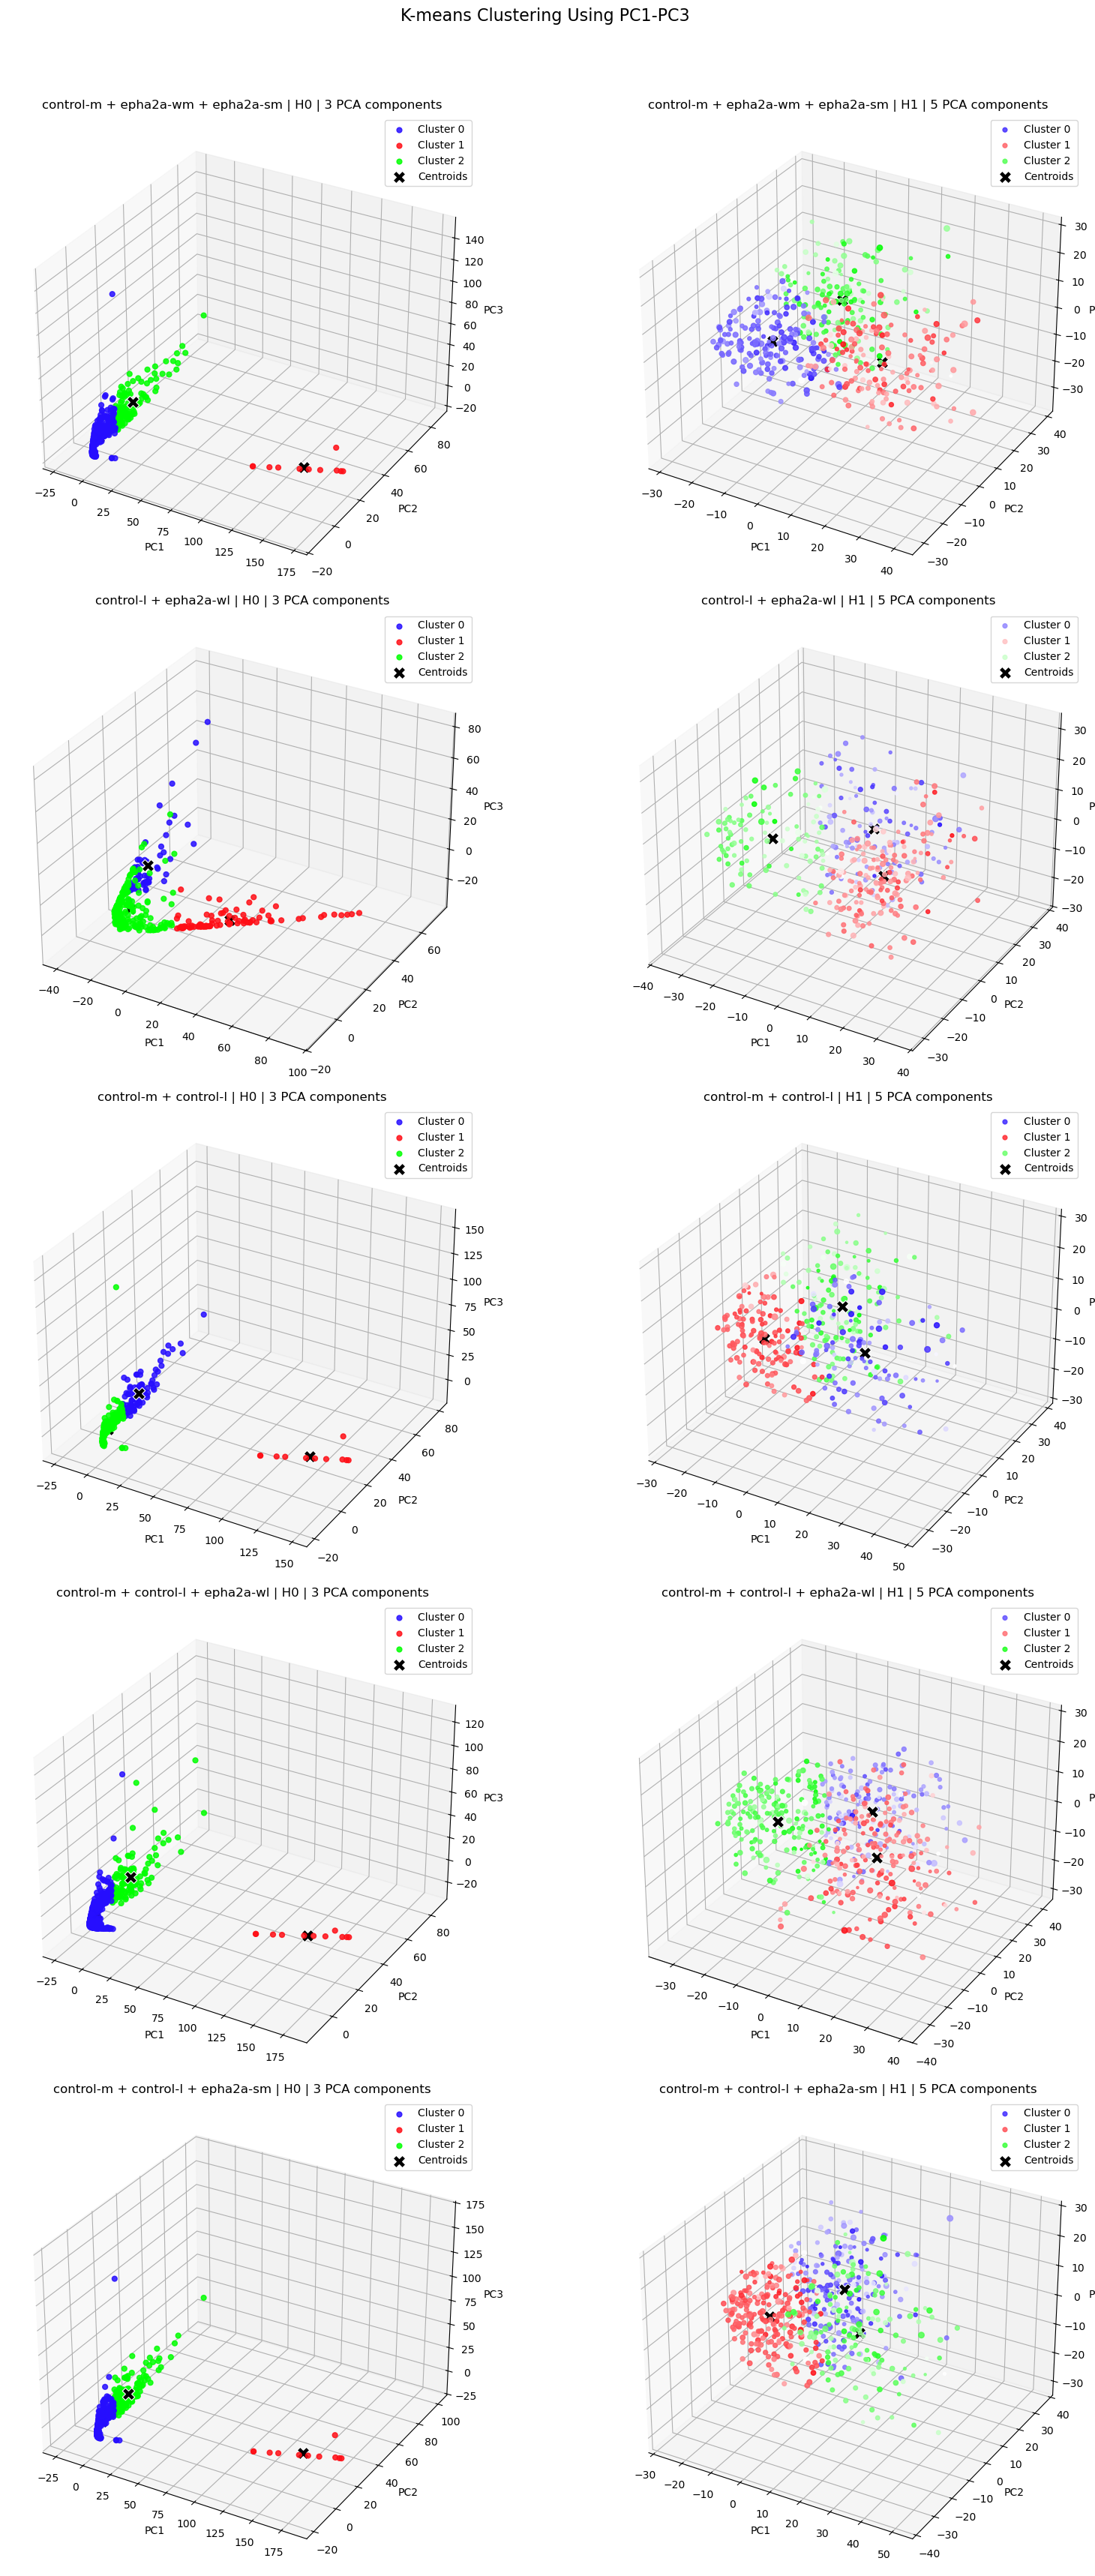

In [10]:
# Cluster PCA scores in three dimensions and encode additional H1 variation with color and size.
# Summary: Cluster the first three PCA components and display centroids, with H1 PC4/PC5 encoded by color brightness and marker size.
# Step 5: Plot K-means clustering.
#
# Column 1: H0
# Column 2: H1
#
# K-means uses PC1-PC3 for both.
# H1:
#   - PC4 controls brightness within each cluster.
#   - PC5 controls marker size within each cluster.
#   - Marker size ranges from 5 to 10.

n_clusters = 3
cluster_colors = ["#260eff", "#ff0e16", "#00ff00"]

n_rows = max(
    1,
    len(h0_clustering_results),
    len(h1_clustering_results),
)

fig = plt.figure(figsize=(18, 7 * n_rows))

# Create one 3D axis per H0/H1 comparison.
for column, results in enumerate(
    (h0_clustering_results, h1_clustering_results)
):
    for row, result in enumerate(results):
        transformed = result["transformed"]
        is_h1 = column == 1

        required_components = 5 if is_h1 else 3

        if (
            transformed.ndim != 2
            or transformed.shape[1] < required_components
        ):
            raise ValueError(
                f"{'H1' if is_h1 else 'H0'} requires at least "
                f"{required_components} PCA components."
            )

        cluster_scores = transformed[:, :3]

        kmeans = KMeans(
            n_clusters=n_clusters,
            random_state=42,
            n_init=10,
        )
# Fit K-means using PC1-PC3 and retain the assigned labels.
        kmeanData = kmeans.fit(cluster_scores)
        labels = kmeanData.labels_

        ax = fig.add_subplot(
            n_rows,
            2,
            row * 2 + column + 1,
            projection="3d",
        )

# Draw each cluster with its configured visual encoding.
        for cluster_id in range(n_clusters):
            selected = labels == cluster_id

            if not np.any(selected):
                continue

            base_color = np.asarray(
                to_rgb(
                    cluster_colors[
                        cluster_id % len(cluster_colors)
                    ]
                )
            )

            if is_h1:
                pc4_values = transformed[selected, 3]
                pc5_values = transformed[selected, 4]

                brightness = normalize(
                    pc4_values,
                    low=0.0,
                    high=1.0,
                    default=0.5,
                )

                # Blend the original cluster color toward white.
                point_colors = (
                    base_color[None, :] * (1 - brightness[:, None])
                    + brightness[:, None]
                )

                marker_sizes = normalize(
                    pc5_values,
                    low=5.0,
                    high=30.0,
                    default=7.5,
                )
            else:
                point_colors = base_color
                marker_sizes = 24

            ax.scatter(
                cluster_scores[selected, 0],
                cluster_scores[selected, 1],
                cluster_scores[selected, 2],
                s=marker_sizes,
                color=point_colors,
                alpha=0.85,
                label=f"Cluster {cluster_id}",
            )

# Overlay the learned cluster centers as black X markers.
        centroids = kmeans.cluster_centers_

        ax.scatter(
            centroids[:, 0],
            centroids[:, 1],
            centroids[:, 2],
            s=140,
            marker="X",
            color="black",
            edgecolors="white",
            linewidths=0.8,
            depthshade=False,
            label="Centroids",
        )

        ax.set_title(
            plot_title(
                result["pca_key"],
                result["requested_components"],
            )
        )
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.set_zlabel("PC3")
        ax.legend(loc="best")
        ax.grid(True)

    for row in range(len(results), n_rows):
        ax = fig.add_subplot(
            n_rows,
            2,
            row * 2 + column + 1,
            projection="3d",
        )
        ax.set_visible(False)

fig.suptitle(
    "K-means Clustering Using PC1-PC3",
    fontsize=16,
)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()


# Conclusion: The 3D figures show cluster assignments, centroids, and H1-specific visual encodings.


In [ ]:
# Create an interactive 3D PCA viewer with cluster selection and camera controls.
# Summary: Build an interactive Plotly 3D viewer with dropdown plot selection, camera sliders, hover metadata, and centroids.
import ipywidgets as widgets
import numpy as np
import plotly.graph_objects as go
from IPython.display import display
from sklearn.cluster import KMeans
from matplotlib.colors import to_rgb, to_hex


cluster_colors = ["#260eff", "#ff0e16", "#00ff00"]
n_clusters = 3


def cell11_title(result):
    conditions = result["pca_key"]["condition"]
    if isinstance(conditions, str):
        conditions = [conditions]

    properties = ", ".join(
        f"H{prop}" for prop in result["pca_key"]["properties"]
    )

    return (
        f"{' + '.join(conditions)} | "
        f"{properties} | "
        f"{result['requested_components']} PCA components"
    )


def normalize_values(values, low, high, default):
    if np.ptp(values) == 0:
        return np.full(values.shape, default)

    return np.interp(
        values,
        (values.min(), values.max()),
        (low, high),
    )


def blend_color_with_white(color, brightness):
    base_color = np.asarray(to_rgb(color))
    blended_color = (
        base_color * (1.0 - brightness)
        + np.ones(3) * brightness
    )
    return to_hex(blended_color)


plot_picker = widgets.Dropdown(
    options=[
        (f"{i + 1}: {cell11_title(result)}", i)
        for i, result in enumerate(clustering_results)
    ],
    value=0,
    description="Plot",
    layout=widgets.Layout(width="700px"),
)

elevation_slider = widgets.IntSlider(
    value=25,
    min=-90,
    max=90,
    step=1,
    description="Elevation",
    continuous_update=False,
)

azimuth_slider = widgets.IntSlider(
    value=-60,
    min=-180,
    max=180,
    step=1,
    description="Azimuth",
    continuous_update=False,
)


def show_selected_pca_plot(plot_index, elevation, azimuth):
    result = clustering_results[plot_index]
    transformed = np.asarray(result["transformed"])
    pca_result = result["pca_result"]

    is_h1 = 1 in result["pca_key"]["properties"]
    required_components = 5 if is_h1 else 3

    if transformed.ndim != 2 or transformed.shape[1] < required_components:
        raise ValueError(
            f"{'H1' if is_h1 else 'H0'} requires at least "
            f"{required_components} PCA components."
        )

    cluster_scores = transformed[:, :3]

    kmeans = KMeans(
        n_clusters=n_clusters,
        random_state=42,
        n_init=10,
    )
    kmeanData = kmeans.fit(cluster_scores)
    labels = kmeanData.labels_  

    row_order = pca_result["row_order"]
    explained_variance_ratio = np.asarray(
        pca_result["explained_variance_ratio"]
    )

    fig = go.Figure()

# Add sample points cluster by cluster, including metadata for hover text.
    for cluster_id in range(n_clusters):
        indices = np.flatnonzero(labels == cluster_id)

        if len(indices) == 0:
            continue

        customdata = [
            [
                manager.groups[row_order[idx][0]].embryo_name,
                manager.groups[row_order[idx][0]].condition,
                manager.groups[row_order[idx][0]].timestep,
                row_order[idx][1],
            ]
            for idx in indices
        ]

        base_color = cluster_colors[
            cluster_id % len(cluster_colors)
        ]

        if is_h1:
            pc4_values = transformed[indices, 3]
            pc5_values = transformed[indices, 4]

            brightness = normalize_values(
                pc4_values,
                low=0.0,
                high=1.0,
                default=0.5,
            )
            marker_sizes = normalize_values(
                pc5_values,
                low=5.0,
                high=10.0,
                default=7.5,
            )

            point_colors = [
                blend_color_with_white(base_color, value)
                for value in brightness
            ]

            customdata = [
                row + [pc4, pc5]
                for row, pc4, pc5 in zip(
                    customdata,
                    pc4_values,
                    pc5_values,
                )
            ]
        else:
            point_colors = base_color
            marker_sizes = 5

        hovertemplate = (
            "Cluster: %{fullData.name}<br>"
            "Embryo: %{customdata[0]}<br>"
            "Condition: %{customdata[1]}<br>"
            "Timestep: %{customdata[2]}<br>"
            "Property: H%{customdata[3]}<br>"
            "PC1: %{x:.3f}<br>"
            "PC2: %{y:.3f}<br>"
            "PC3: %{z:.3f}"
        )

        if is_h1:
            hovertemplate += (
                "<br>PC4: %{customdata[4]:.3f}"
                "<br>PC5: %{customdata[5]:.3f}"
            )

        fig.add_trace(
            go.Scatter3d(
                x=cluster_scores[indices, 0],
                y=cluster_scores[indices, 1],
                z=cluster_scores[indices, 2],
                customdata=customdata,
                mode="markers",
                name=f"Cluster {cluster_id}",
                legendgroup=f"cluster-{cluster_id}",
                marker={
                    "size": marker_sizes,
                    "color": point_colors,
                    "opacity": 0.85,
                },
                hovertemplate=hovertemplate + "<extra></extra>",
            )
        )

# Add centroid markers so cluster locations are easy to compare.
    centroids = kmeans.cluster_centers_

    fig.add_trace(
        go.Scatter3d(
            x=centroids[:, 0],
            y=centroids[:, 1],
            z=centroids[:, 2],
            mode="markers",
            name="Centroids",
            marker={
                "size": 9,
                "symbol": "x",
                "color": "black",
                "line": {
                    "color": "white",
                    "width": 2,
                },
            },
            customdata=np.arange(n_clusters).reshape(-1, 1),
            hovertemplate=(
                "Centroid for Cluster %{customdata[0]}<br>"
                "PC1: %{x:.3f}<br>"
                "PC2: %{y:.3f}<br>"
                "PC3: %{z:.3f}"
                "<extra></extra>"
            ),
        )
    )

    axis_ranges = []

    for component in range(3):
        minimum = float(cluster_scores[:, component].min())
        maximum = float(cluster_scores[:, component].max())
        padding = (
            (maximum - minimum) * 0.05
            if maximum > minimum
            else 0.1
        )
        axis_ranges.append(
            [minimum - padding, maximum + padding]
        )

# Convert slider angles into a Plotly camera position.
    elevation_rad = np.deg2rad(elevation)
    azimuth_rad = np.deg2rad(azimuth)
    camera_distance = 1.8

    camera_eye = {
        "x": (
            camera_distance
            * np.cos(elevation_rad)
            * np.cos(azimuth_rad)
        ),
        "y": (
            camera_distance
            * np.cos(elevation_rad)
            * np.sin(azimuth_rad)
        ),
        "z": camera_distance * np.sin(elevation_rad),
    }

    fig.update_layout(
        title=cell11_title(result),
        height=750,
        width=950,
        autosize=False,
        margin={"l": 0, "r": 0, "t": 50, "b": 0},
        scene={
            "xaxis": {
                "title": f"PC1 ({explained_variance_ratio[0]:.1%})",
                "range": axis_ranges[0],
                "autorange": False,
            },
            "yaxis": {
                "title": f"PC2 ({explained_variance_ratio[1]:.1%})",
                "range": axis_ranges[1],
                "autorange": False,
            },
            "zaxis": {
                "title": f"PC3 ({explained_variance_ratio[2]:.1%})",
                "range": axis_ranges[2],
                "autorange": False,
            },
            "camera": {"eye": camera_eye},
            "aspectmode": "cube",
            "aspectratio": {
                "x": 1,
                "y": 1,
                "z": 1,
            },
            "uirevision": f"pca-plot-{plot_index}",
        },
        uirevision=f"pca-plot-{plot_index}",
    )
    return fig


# Link widget changes to the plotting function and display the controls.
plot_output = widgets.interactive_output(
    show_selected_pca_plot,
    {
        "plot_index": plot_picker,
        "elevation": elevation_slider,
        "azimuth": azimuth_slider,
    },
)

display(
    widgets.VBox(
        [
            widgets.HBox([plot_picker]),
            widgets.HBox(
                [elevation_slider, azimuth_slider]
            ),
            plot_output,
        ]
    )
)


# Conclusion: Users can inspect each PCA grouping interactively and compare cluster structure across views.


In [21]:
help(widgets.interactive_output)

Help on function interactive_output in module ipywidgets.widgets.interaction:

interactive_output(f, controls)
    Connect widget controls to a function.

    This function does not generate a user interface for the widgets (unlike `interact`).
    This enables customisation of the widget user interface layout.
    The user interface layout must be defined and displayed manually.



In [16]:
help(plot_output)

Help on Output in module ipywidgets.widgets.widget_output object:

class Output(ipywidgets.widgets.domwidget.DOMWidget)
 |  Output(**kwargs)
 |
 |  Widget used as a context manager to display output.
 |
 |  This widget can capture and display stdout, stderr, and rich output.  To use
 |  it, create an instance of it and display it.
 |
 |  You can then use the widget as a context manager: any output produced while in the
 |  context will be captured and displayed in the widget instead of the standard output
 |  area.
 |
 |  You can also use the .capture() method to decorate a function or a method. Any output
 |  produced by the function will then go to the output widget. This is useful for
 |  debugging widget callbacks, for example.
 |
 |  Example::
 |      import ipywidgets as widgets
 |      from IPython.display import display
 |      out = widgets.Output()
 |      display(out)
 |
 |      print('prints to output area')
 |
 |      with out:
 |          print('prints to output widget')


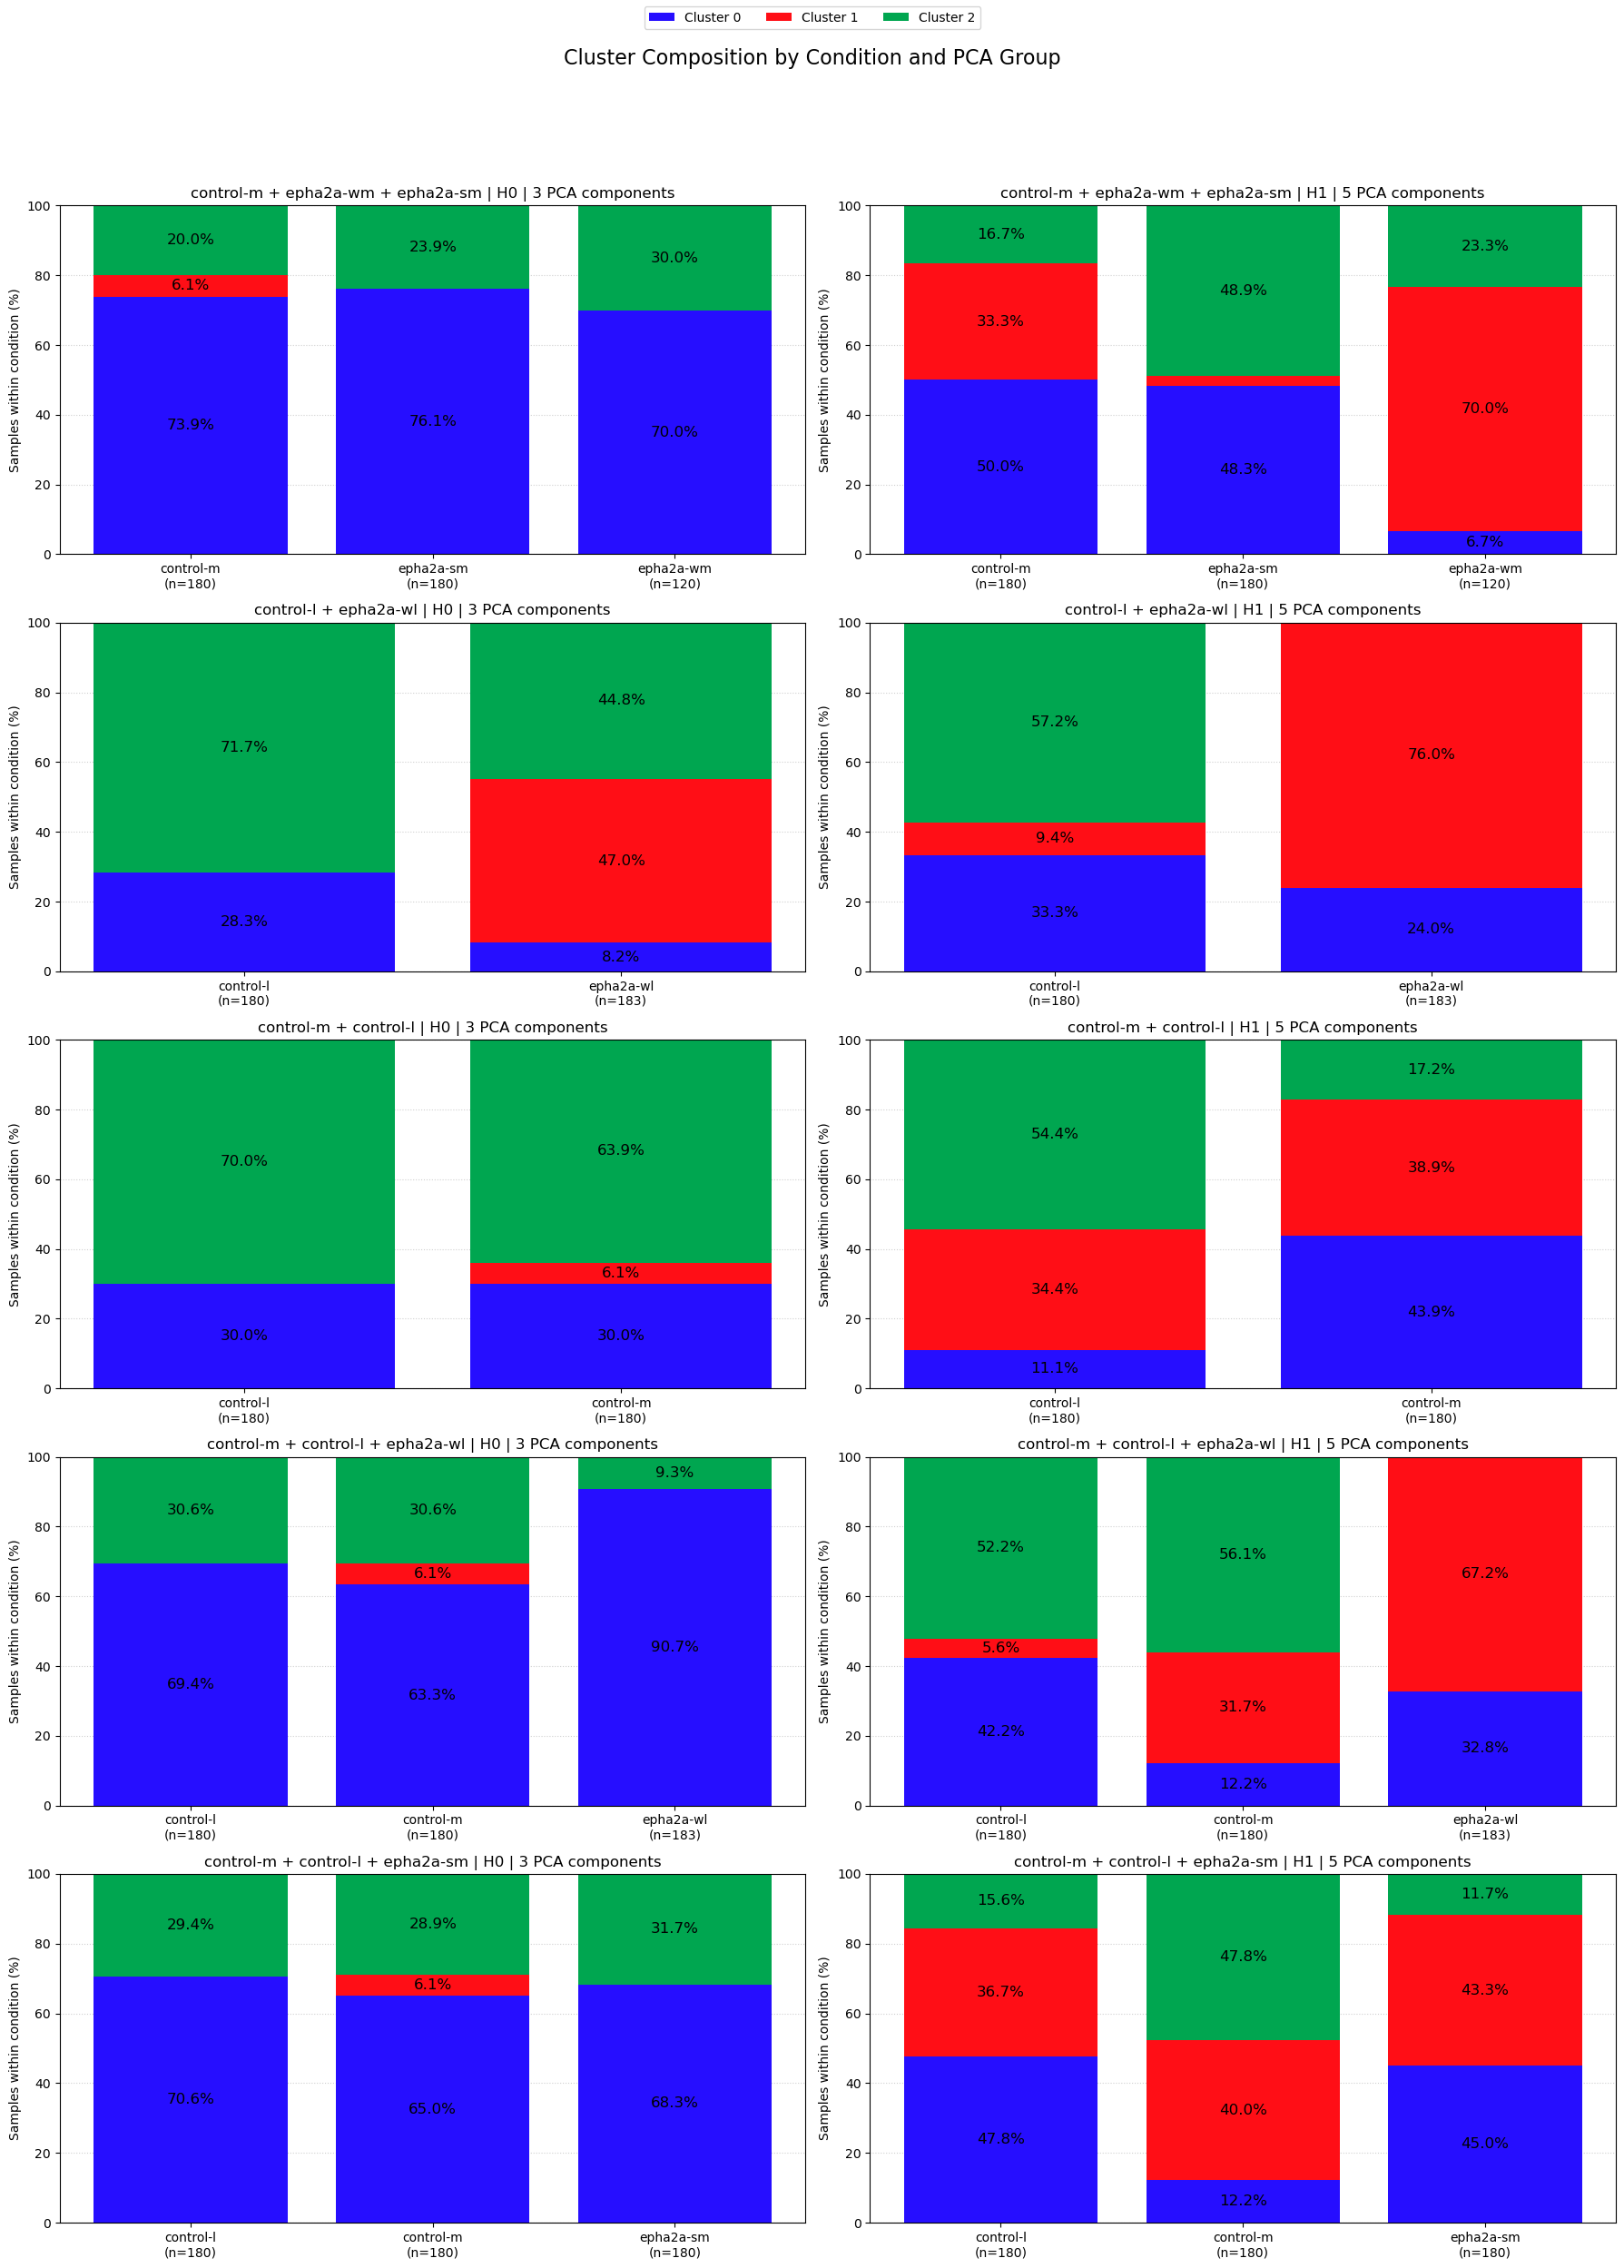

In [13]:
# Calculate and visualize the percentage composition of each cluster within every condition.
# Summary: Assign samples to K-means clusters and show each condition’s cluster percentages as stacked bars.
from sklearn.cluster import KMeans

composition_colors = [
    "#260eff",
    "#ff0e16",
    "#00a650",
    "#9467bd",
    "#ff7f0e",
]

n_clusters = 3
composition_results = []

if len(h0_clustering_results) != len(h1_clustering_results):
    raise ValueError(
        "H0 and H1 clustering results must have the same length "
        "to keep H0 in column 1 and H1 in column 2."
    )

# Interleave H0 and H1 records so they appear side by side in the figure.
all_clustering_results = [
    result
    for h0_result, h1_result in zip(
        h0_clustering_results,
        h1_clustering_results,
    )
    for result in (h0_result, h1_result)
]

n_rows = max(
    1,
    int(np.ceil(len(all_clustering_results) / 2)),
)

composition_fig, composition_axes = plt.subplots(
    n_rows,
    2,
    figsize=(18, 5 * n_rows),
    squeeze=False,
)

# Compute cluster membership and condition composition for each plot.
for plot_index, result in enumerate(all_clustering_results):
    transformed = np.asarray(result["transformed"])
    row_order = result["pca_result"]["row_order"]

    if len(transformed) != len(row_order):
        raise ValueError(
            f"Plot group {plot_index + 1} has "
            f"{len(transformed)} PCA rows but "
            f"{len(row_order)} metadata rows."
        )

    cluster_scores = transformed[:, :3]

    kmeans = KMeans(
        n_clusters=n_clusters,
        random_state=42,
        n_init=10,
    )
    kmeandata = kmeans.fit(cluster_scores)
    labels = kmeandata.labels_

# Preserve the first-seen order of experimental conditions.
    conditions = list(
        dict.fromkeys(
            manager.groups[group_id].condition
            for group_id, _ in row_order
        )
    )

    cluster_ids = list(range(n_clusters))
    counts = np.zeros(
        (n_clusters, len(conditions)),
        dtype=int,
    )
    totals = np.zeros(
        len(conditions),
        dtype=int,
    )

    condition_index = {
        condition: index
        for index, condition in enumerate(conditions)
    }

    for label, (group_id, _) in zip(labels, row_order):
        condition = manager.groups[group_id].condition
        condition_position = condition_index[condition]

        counts[int(label), condition_position] += 1
        totals[condition_position] += 1

# Convert counts to within-condition percentages without dividing by zero.
    percentages = np.divide(
        counts * 100,
        totals[np.newaxis, :],
        out=np.zeros_like(counts, dtype=float),
        where=totals[np.newaxis, :] != 0,
    )

    plot_title_text = plot_title(
        result["pca_key"],
        result["requested_components"],
    )

    composition_results.append(
        {
            "title": plot_title_text,
            "conditions": conditions,
            "counts": counts,
            "totals": totals,
            "percentages": percentages,
            "labels": labels,
            "row_order": row_order,
            "kmeans": kmeans,
        }
    )

    ax = composition_axes.flat[plot_index]
    x = np.arange(len(conditions))
    bottom = np.zeros(len(conditions))

# Draw the percentage contribution of each cluster as a stacked bar segment.
    for cluster_position, cluster_id in enumerate(cluster_ids):
        values = percentages[cluster_position]

        bars = ax.bar(
            x,
            values,
            bottom=bottom,
            color=composition_colors[
                cluster_position % len(composition_colors)
            ],
            label=f"Cluster {cluster_id}",
        )

        for condition_position, bar in enumerate(bars):
            value = values[condition_position]

            if value >= 5:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bottom[condition_position] + value / 2,
                    f"{value:.1f}%",
                    ha="center",
                    va="center",
                    fontsize=12,
                )

        bottom += values

    ax.set_title(plot_title_text)
    ax.set_xticks(
        x,
        [
            f"{condition}\n(n={total})"
            for condition, total in zip(conditions, totals)
        ],
    )
    ax.set_ylim(0, 100)
    ax.set_ylabel("Samples within condition (%)")
    ax.grid(axis="y", linestyle=":", alpha=0.6)
    ax.set_axisbelow(True)

for ax in composition_axes.flat[len(all_clustering_results):]:
    ax.set_visible(False)

composition_fig.suptitle(
    "Cluster Composition by Condition and PCA Group",
    fontsize=16,
)

handles, legend_labels = (
    composition_axes.flat[0].get_legend_handles_labels()
)

composition_fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    ncol=n_clusters,
)

composition_fig.tight_layout(
    rect=(0, 0, 1, 0.94),
)

plt.show()

# Conclusion: The stacked bars summarize how cluster membership is distributed across experimental conditions.


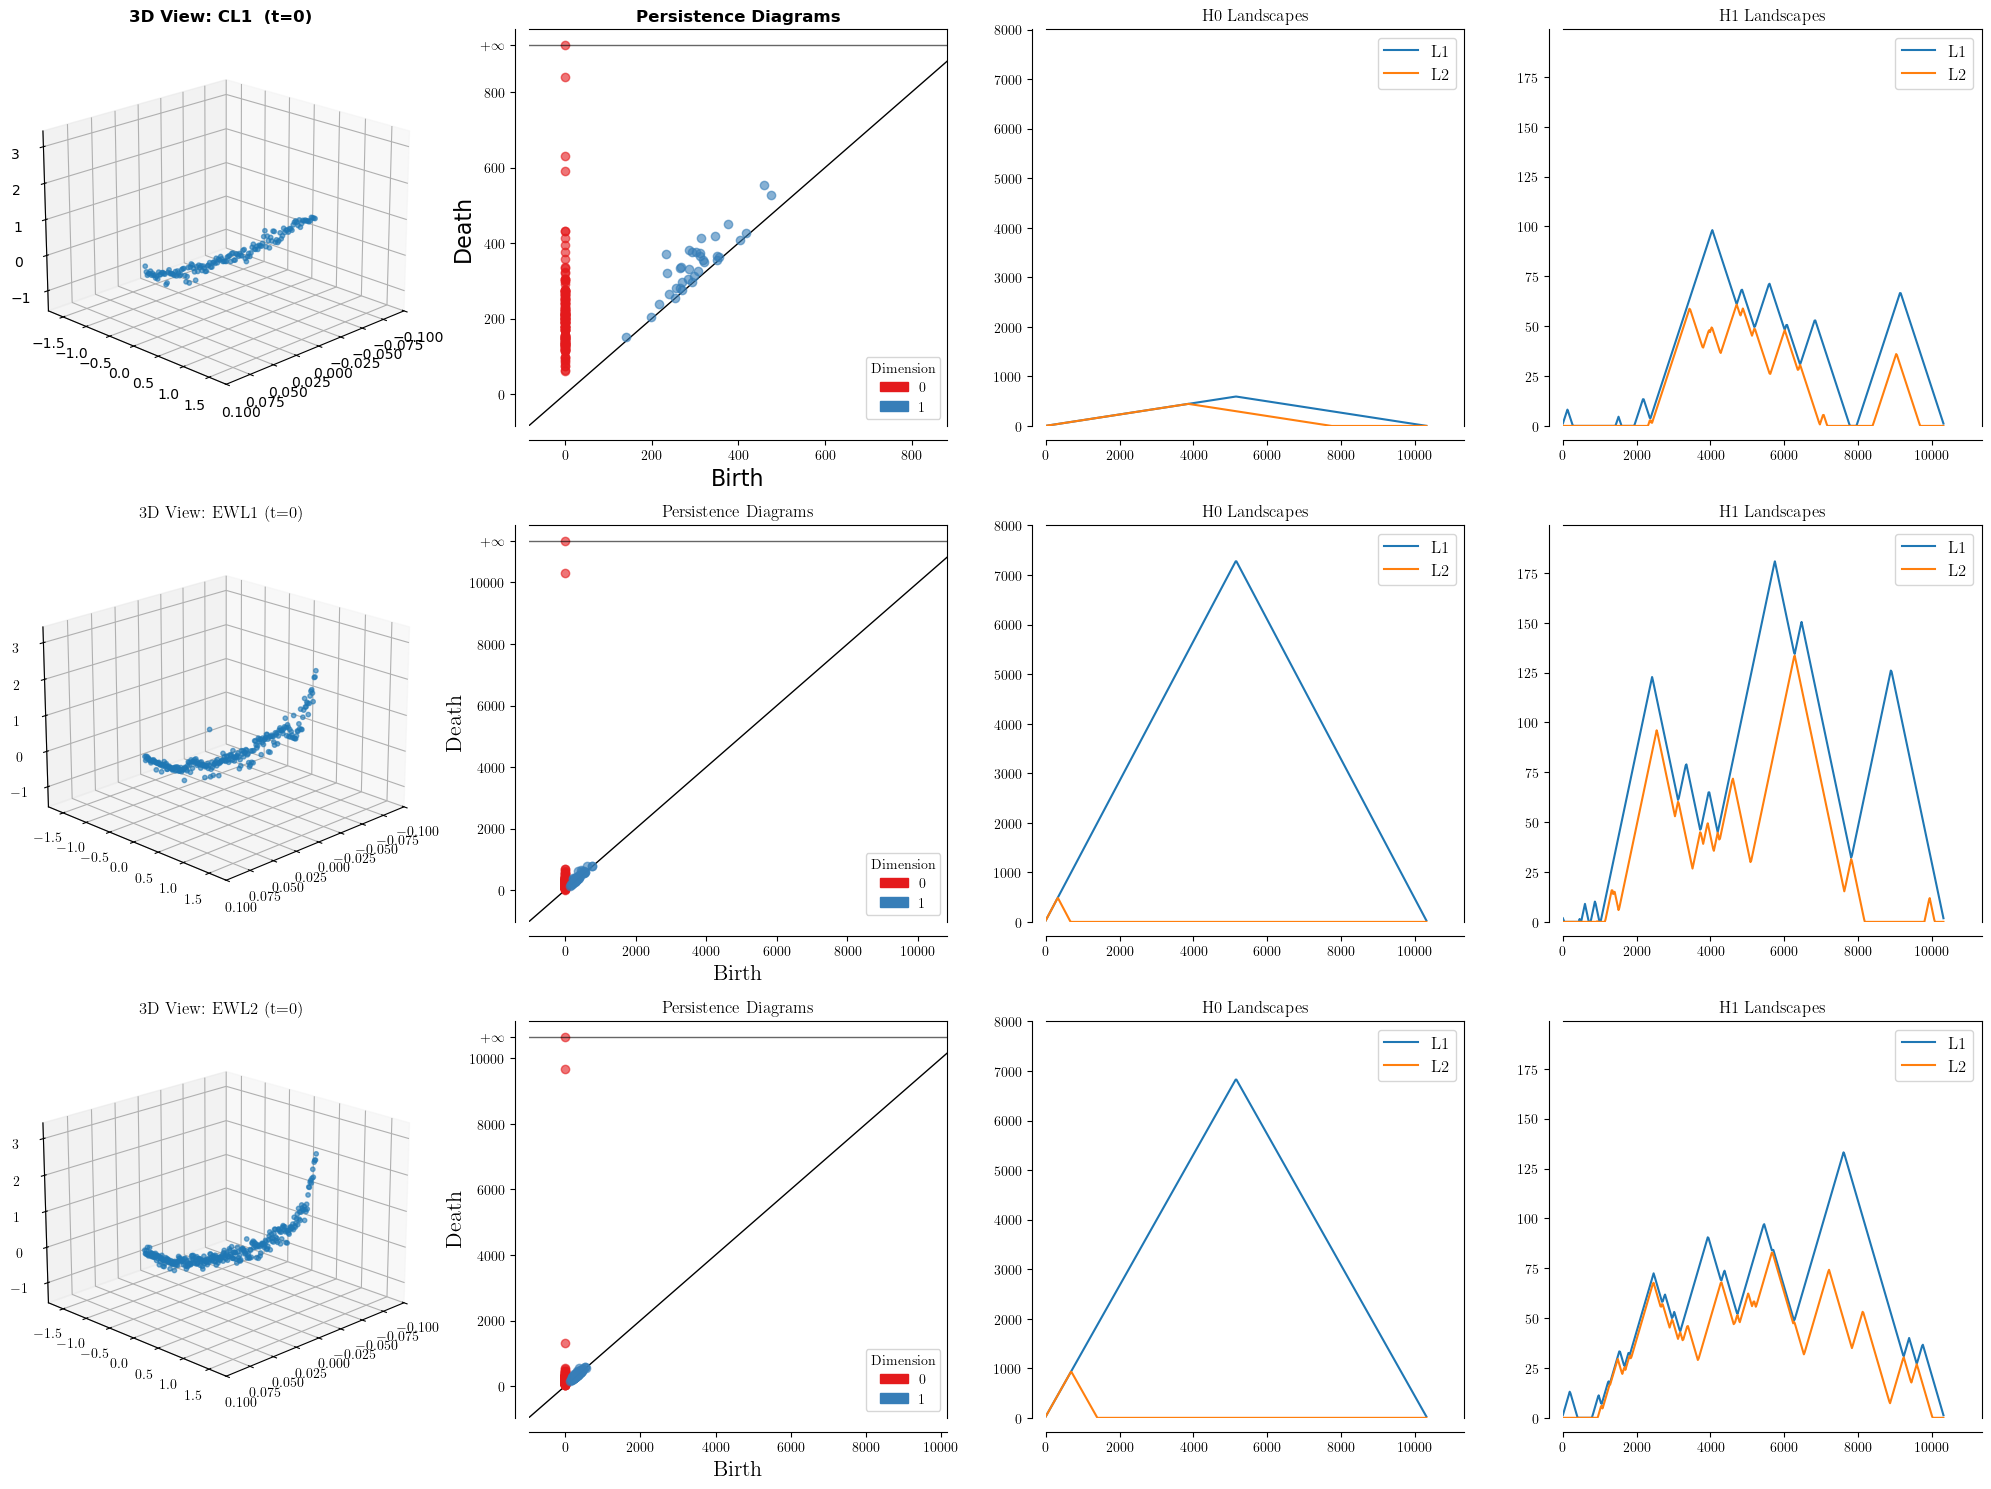

In [ ]:
EMW1 = ("EWL1",0)
EMW2 = ("EWL2",0)
CL1 = ("CL1 ",0)
manager.Plotter.compare_tda_summaries([CL1, EMW1, EMW2])
# manager.list_group_ids()